# Tableau de bord — suivi de production de l'API de scoring

Analyse des données de production réellement journalisées par l'API : dérive des
données, dérive des prédictions et santé du service.

Ce notebook **n'implémente aucune logique** : il appelle le module `monitoring`, le même
que `scripts/analyze_production.py`. Les chiffres affichés ici sont donc, par
construction, ceux du rapport automatique — un seul endroit à corriger en cas d'erreur.

**Prérequis** : avoir généré du trafic et ingéré les journaux.

```bash
python scripts/simulate_traffic.py --n 250
python scripts/simulate_traffic.py --n 180 --profil derive --erreurs 24
python scripts/analyze_production.py
```

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

from monitoring import drift, operations, storage

# Palette : bleu = référence d'entraînement, orange = production (créneaux 1 et 2 de la
# palette de référence du projet, validés pour les daltonismes sur paires adjacentes).
REFERENCE, PRODUCTION = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.figsize": (9, 3.4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
                     "font.size": 10, "axes.titlesize": 11, "figure.dpi": 110})

reference = pd.read_csv(RACINE / "model" / "reference_drift.csv")
features = [c for c in reference.columns if c not in {"probabilite_defaut", "decision", "TARGET"}]
base = RACINE / "monitoring" / "production.db"

requetes = storage.charger_requetes(base)
predictions = storage.charger_predictions(base, features=features)
reussies = predictions[predictions["statut"] == 200]
seuil = float(reussies["seuil"].dropna().iloc[0])

print(f"{len(requetes)} requêtes, {len(predictions)} appels au modèle "
      f"({len(reussies)} aboutis), seuil métier {seuil:.3f}")
print("Période :", requetes["horodatage"].min(), "→", requetes["horodatage"].max())
storage.volumetrie(base)

1000 requêtes, 979 appels au modèle (943 aboutis), seuil métier 0.080
Période : 2026-10-08T10:47:21.437708+00:00 → 2026-10-08T15:14:14.698047+00:00


{'evenements': 1979,
 'predictions': 979,
 'taille_base_mo': 32.58,
 'octets_par_prediction': 33283}

## 1. Santé du service

Le taux d'erreur et la latence se lisent sur les événements `requete`, qui couvrent
**toutes** les routes et tous les statuts — y compris les `401` (clé invalide) et les
`422` (entrée refusée), invisibles dans les seules prédictions abouties.

In [2]:
exploitation = operations.analyser(requetes)

print(f"Verdict : {exploitation['niveau']}")
print(f"  succès 2xx        : {exploitation['taux_succes']:.1%}")
print(f"  erreurs client 4xx: {exploitation['taux_erreur_client']:.1%}")
print(f"  erreurs serveur 5xx: {exploitation['taux_erreur_serveur']:.1%}")
print(f"  latence /predict  : p50 {exploitation['latences_ms']['p50']:.0f} ms, "
      f"p95 {exploitation['latences_ms']['p95']:.0f} ms, "
      f"p99 {exploitation['latences_ms']['p99']:.0f} ms")
for anomalie in exploitation["anomalies"]:
    print("  ⚠", anomalie)

pd.DataFrame(operations.erreurs_frequentes(predictions))

Verdict : STABLE
  succès 2xx        : 94.7%
  erreurs client 4xx: 5.3%
  erreurs serveur 5xx: 0.0%
  latence /predict  : p50 34 ms, p95 116 ms, p99 127 ms


,type,message,occurrences
0,OutOfBoundsValues,Valeurs hors bornes : AMT_INCOME_TOTAL = 0 hor...,6
1,OutOfBoundsValues,Valeurs hors bornes : DAYS_BIRTH = 1825 hors d...,6
2,UnknownFeatures,Features inconnues du modèle : REVENU_IMAGINAIRE,6


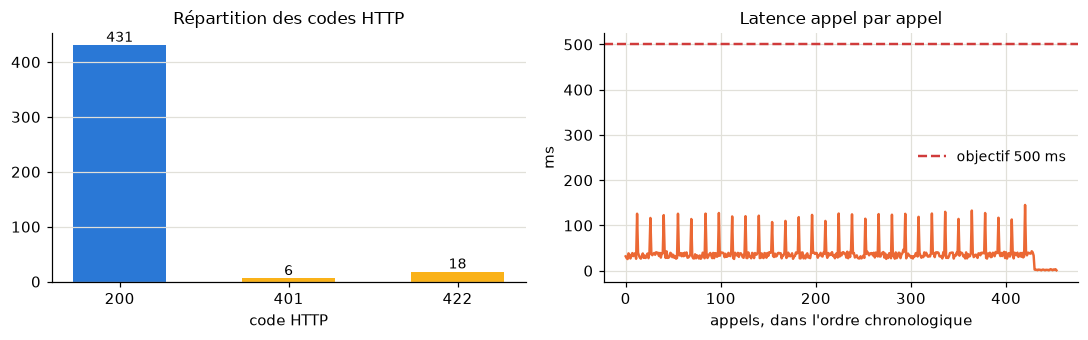

In [3]:
figure, (gauche, droite) = plt.subplots(1, 2, figsize=(10, 3.2))

statuts = pd.Series(exploitation["par_statut"]).sort_index()
couleurs = [REFERENCE if str(s).startswith("2") else "#fab219" if str(s).startswith("4")
            else "#d03b3b" for s in statuts.index]
gauche.bar([str(s) for s in statuts.index], statuts.values, color=couleurs, width=0.55)
gauche.set_title("Répartition des codes HTTP")
gauche.set_xlabel("code HTTP")
gauche.grid(axis="x", visible=False)
for x, valeur in enumerate(statuts.values):
    gauche.annotate(str(valeur), (x, valeur), ha="center", va="bottom", fontsize=9)

latences = requetes.loc[requetes["route"] == "/predict", "latence_ms"].reset_index(drop=True)
droite.plot(latences.index, latences, color=PRODUCTION, linewidth=1.6)
droite.axhline(operations.SEUILS["latence_p95_ms"], color="#d03b3b", linestyle="--",
               linewidth=1.6, label=f"objectif {operations.SEUILS['latence_p95_ms']:.0f} ms")
droite.set_title("Latence appel par appel")
droite.set_xlabel("appels, dans l'ordre chronologique")
droite.set_ylabel("ms")
droite.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 2. Dérive des données

Référence : un échantillon du **jeu d'entraînement** (`model/reference_drift.csv`),
restreint aux 33 features suivies — les 30 plus influentes du modèle et les variables
du dossier client.

Une feature est déclarée en dérive si l'effet est net (**PSI ≥ 0,25**) ou modéré **et**
statistiquement significatif (**Kolmogorov-Smirnov**, seuil corrigé par Bonferroni).
Les deux indicateurs sont nécessaires : KS devient significatif pour des écarts
minuscules dès que le volume monte, et le PSI seul ne dit rien de la fiabilité de
l'écart.

In [4]:
resultats = drift.analyser_features(reference, reussies, features)
synthese = drift.synthese(resultats,
                          drift.analyser_predictions(reference["probabilite_defaut"],
                                                     reussies["probabilite_defaut"], seuil))
print(f"Verdict : {synthese['niveau']} — {synthese['features_en_derive']} feature(s) "
      f"en dérive sur {synthese['features_evaluables']} évaluables")
for motif in synthese["motifs"]:
    print("  ·", motif)

colonnes = ["feature", "psi", "ks_statistique", "ks_p_value",
            "moyenne_reference", "moyenne_production",
            "manquants_reference", "manquants_production", "verdict"]
resultats[colonnes].head(12).style.format({
    "psi": "{:.3f}", "ks_statistique": "{:.3f}", "ks_p_value": "{:.1e}",
    "moyenne_reference": "{:,.4g}", "moyenne_production": "{:,.4g}",
    "manquants_reference": "{:.0%}", "manquants_production": "{:.0%}"})

Verdict : ALERTE — 8 feature(s) en dérive sur 33 évaluables
  · 8 feature(s) en dérive : EXT_SOURCE_3, AMT_GOODS_PRICE, ACTIVE_DAYS_CREDIT_MAX, EXT_SOURCE_1, PAYMENT_RATE
  · dérive de la distribution des scores
  · taux de refus déplacé de +11.3%


,feature,psi,ks_statistique,ks_p_value,moyenne_reference,moyenne_production,manquants_reference,manquants_production,verdict
0,EXT_SOURCE_3,0.232,0.184,4.3e-09,0.5088,0.4261,20%,18%,dérive
1,AMT_GOODS_PRICE,0.189,0.146,4.4e-07,5.308e+05,4.38e+05,0%,0%,dérive
2,ACTIVE_DAYS_CREDIT_MAX,0.178,0.120,9.1e-04,-398.1,-413.8,30%,24%,dérive
3,EXT_SOURCE_1,0.177,0.159,1.0e-04,0.4958,0.415,56%,43%,dérive des valeurs manquantes
4,PAYMENT_RATE,0.173,0.146,5.0e-07,0.05476,0.05773,0%,0%,dérive
5,EXT_SOURCE_2,0.158,0.188,1.8e-11,0.5139,0.4549,0%,0%,dérive
6,DAYS_EMPLOYED,0.133,0.155,1.4e-06,"-2,421","-1,754",18%,17%,dérive
7,OWN_CAR_AGE,0.111,0.064,6.1e-01,11.62,11.98,65%,61%,dérive modérée
8,AMT_INCOME_TOTAL,0.105,0.106,6.6e-04,1.693e+05,1.512e+05,0%,0%,dérive
9,ACTIVE_DAYS_CREDIT_ENDDATE_MIN,0.099,0.103,8.9e-03,829.6,"1,519",33%,27%,stable


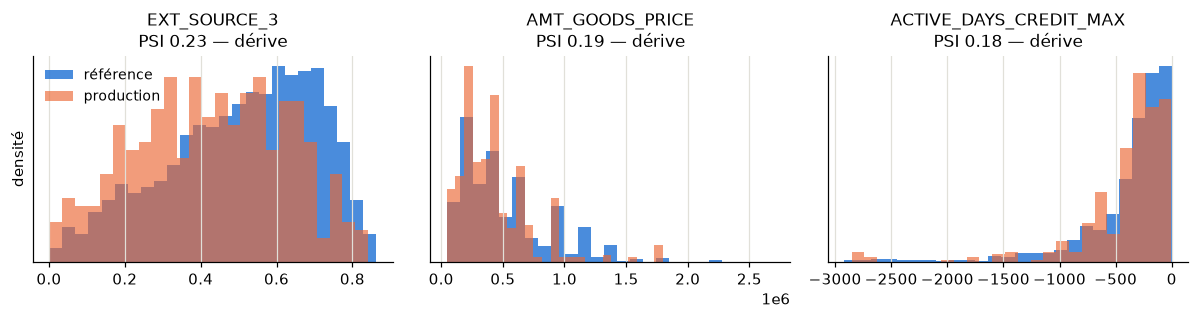

In [5]:
# distributions des trois features les plus décalées
pires = resultats.head(3)
figure, axes = plt.subplots(1, len(pires), figsize=(11, 3))
for axe, ligne in zip(axes, pires.itertuples()):
    bornes = 25
    axe.hist(reference[ligne.feature].dropna(), bins=bornes, density=True,
             color=REFERENCE, alpha=0.85, label="référence")
    axe.hist(reussies[ligne.feature].dropna(), bins=bornes, density=True,
             color=PRODUCTION, alpha=0.65, label="production")
    axe.set_title(f"{ligne.feature}\nPSI {ligne.psi:.2f} — {ligne.verdict}")
    axe.set_yticks([])
axes[0].set_ylabel("densité")
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 3. Dérive des prédictions

Le signal le plus parlant pour le métier : même sans dérive visible sur une feature, un
taux de refus qui bouge de plusieurs points change le coût métier, puisque le seuil de
décision a été optimisé sur la distribution d'entraînement.

  n_reference                  2000
  n_production                 430
  score_moyen_reference        0.0802
  score_moyen_production       0.1015
  taux_refus_reference         0.3035
  taux_refus_production        0.4163
  ecart_taux_refus             0.1128
  psi                          0.0981
  ks_statistique               0.1262
  ks_p_value                   0.0
  verdict                      dérive modérée


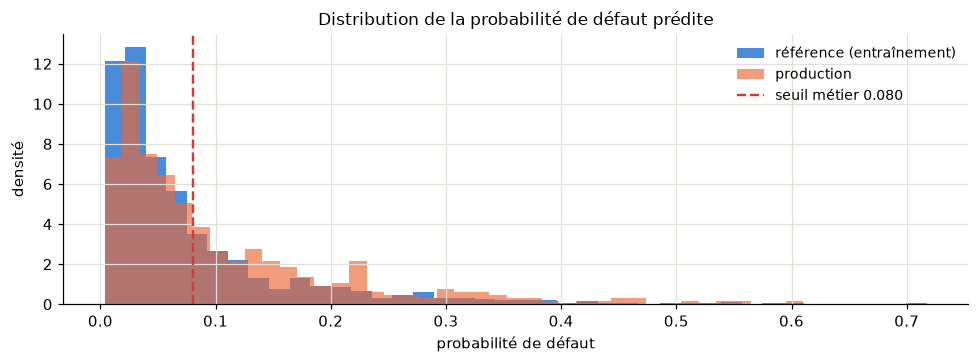

In [6]:
derive_predictions = drift.analyser_predictions(reference["probabilite_defaut"],
                                               reussies["probabilite_defaut"], seuil)
for cle, valeur in derive_predictions.items():
    print(f"  {cle:28s} {valeur if isinstance(valeur, str) else round(valeur, 4)}")

figure, axe = plt.subplots(figsize=(9, 3.4))
axe.hist(reference["probabilite_defaut"], bins=40, density=True, color=REFERENCE,
         alpha=0.85, label="référence (entraînement)")
axe.hist(reussies["probabilite_defaut"].dropna(), bins=40, density=True, color=PRODUCTION,
         alpha=0.65, label="production")
axe.axvline(seuil, color="#d03b3b", linestyle="--", linewidth=1.6,
            label=f"seuil métier {seuil:.3f}")
axe.set_title("Distribution de la probabilité de défaut prédite")
axe.set_xlabel("probabilité de défaut")
axe.set_ylabel("densité")
axe.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 4. Comparaison de deux périodes

L'intérêt d'un suivi n'est pas un chiffre absolu mais son évolution. On compare ici la
première moitié du trafic à la seconde : c'est ce découpage qui distingue une dérive
installée d'une dérive qui vient d'apparaître.

In [7]:
milieu = len(reussies) // 2
periodes = {"première moitié": reussies.iloc[:milieu], "seconde moitié": reussies.iloc[milieu:]}

comparaison = []
for nom, lot in periodes.items():
    resultats_lot = drift.analyser_features(reference, lot, features)
    predictions_lot = drift.analyser_predictions(reference["probabilite_defaut"],
                                                 lot["probabilite_defaut"], seuil)
    comparaison.append({
        "période": nom,
        "appels": len(lot),
        "features en dérive": int((resultats_lot["verdict"] == "dérive").sum()),
        "PSI max": round(resultats_lot["psi"].max(), 3),
        "PSI scores": round(predictions_lot["psi"], 3),
        "taux de refus": f"{predictions_lot['taux_refus_production']:.1%}",
        "écart au taux de référence": f"{predictions_lot['ecart_taux_refus']:+.1%}",
    })
pd.DataFrame(comparaison).set_index("période")

,appels,features en dérive,PSI max,PSI scores,taux de refus,écart au taux de référence
période,,,,,,
première moitié,215,3,1.307,0.041,31.6%,+1.3%
seconde moitié,215,7,1.573,0.412,51.6%,+21.3%


## 5. Points de vigilance

1. **Une dérive des features ne se traduit pas mécaniquement en dérive des décisions.**
   Sur du trafic nominal, `PAYMENT_RATE` dérive franchement alors que le taux de refus
   ne bouge que de ~1,5 point. Surveiller les deux : les entrées alertent tôt, les
   sorties mesurent l'impact métier.
2. **Le jeu test de Home Credit dérive réellement du jeu d'entraînement** — médiane de
   `PAYMENT_RATE` 0,050 contre 0,061, crédits plus petits. C'est une fenêtre temporelle
   postérieure, pas un tirage aléatoire : toute « production » tirée du jeu test porte
   donc une dérive de fond, qu'il faut distinguer d'un incident.
3. **Le seuil de 0,080 est lié à la distribution d'entraînement.** Il doit être
   réévalué quand la population bouge, pas seulement quand le modèle est réentraîné.
4. **Les valeurs manquantes sont un angle mort** : LightGBM les accepte sans erreur,
   donc une feature qui cesse d'être alimentée dégrade le score en silence. D'où leur
   suivi séparé du PSI.
5. **La référence vieillit** : elle accompagne le modèle `@champion`. Après tout
   réentraînement, régénérer `model/reference_drift.csv` (`scripts/export_model.py`).

Le même diagnostic s'obtient sans notebook, avec un code de sortie exploitable par une
tâche planifiée :

```bash
python scripts/analyze_production.py   # code 1 si ALERTE, rapport dans rapports/
```